# 5. Analyse en composantes principales (ACP)

Réduction des 11 variables physico-chimiques à quelques axes pour visualiser leur structure et la position des vins selon leur qualité.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("../data/processed/winequality_cleaned.csv")

## Préparation et standardisation
On exclut la cible `quality`. Les variables n'ont pas les mêmes unités (pH, g/L, mg/L…), donc on les centre et on les réduit.

In [2]:
X = data.drop(columns=['quality'])
features = X.columns

X_scaled = StandardScaler().fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)
ratio = pca.explained_variance_ratio_

pd.DataFrame({'Variance expliquée': ratio, 'Variance cumulée': np.cumsum(ratio)},
             index=[f'F{i+1}' for i in range(len(ratio))]).round(3)

,Variance expliquée,Variance cumulée
F1,0.283,0.283
F2,0.173,0.456
F3,0.141,0.597
F4,0.114,0.711
F5,0.087,0.798
F6,0.058,0.856
F7,0.053,0.909
F8,0.037,0.947
F9,0.031,0.978
F10,0.016,0.995


## A. Éboulis des valeurs propres

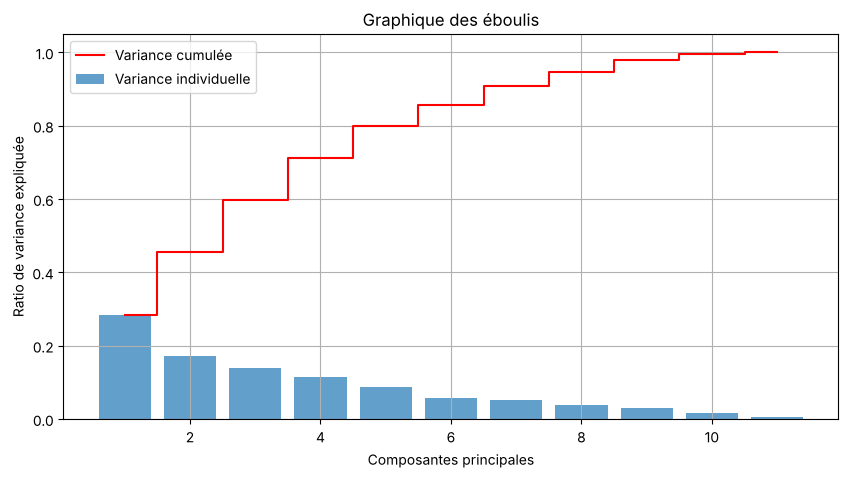

In [3]:
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(ratio) + 1), ratio, alpha=0.7, label='Variance individuelle')
plt.step(range(1, len(ratio) + 1), np.cumsum(ratio), where='mid', label='Variance cumulée', color='red')
plt.ylabel('Ratio de variance expliquée')
plt.xlabel('Composantes principales')
plt.title('Graphique des éboulis')
plt.legend()
plt.grid(True)
plt.show()

## B. Cercle des corrélations (F1 × F2)
Les coordonnées des flèches sont les corrélations entre chaque variable et les axes (vecteurs propres × racine des valeurs propres).

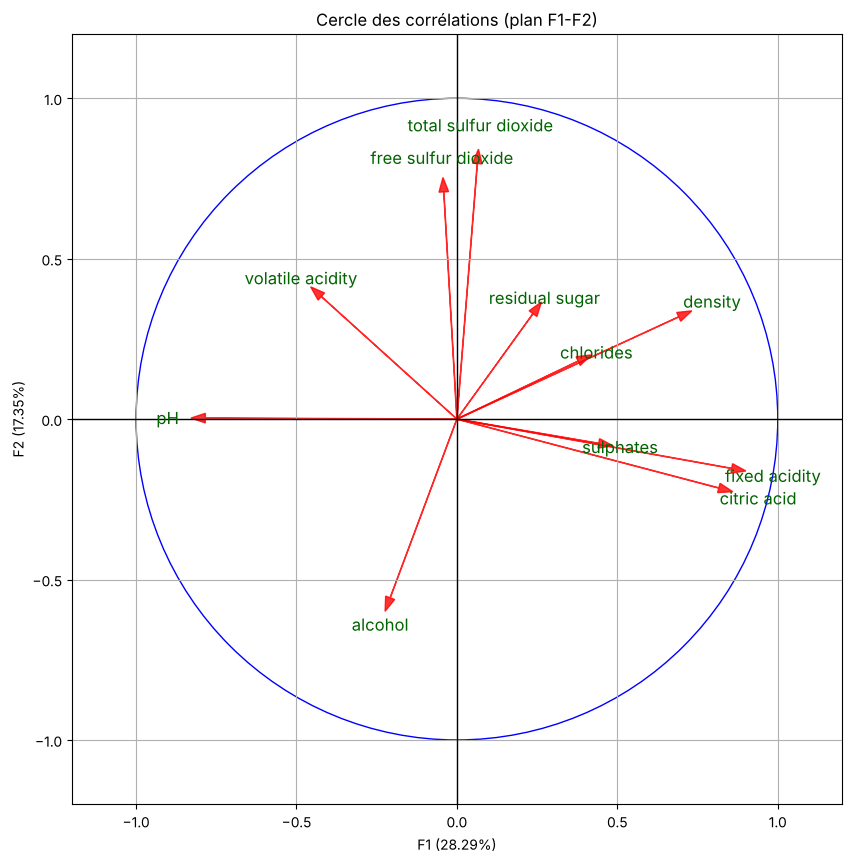

In [4]:
correlations = pca.components_.T * np.sqrt(pca.explained_variance_)

plt.figure(figsize=(10, 10))
for i, (x, y) in enumerate(correlations[:, :2]):
    plt.arrow(0, 0, x, y, color='r', alpha=0.8, head_width=0.03)
    plt.text(x * 1.15, y * 1.15, features[i], color='darkgreen', ha='center', va='center', fontsize=12)

plt.gca().add_artist(plt.Circle((0, 0), 1, color='blue', fill=False))
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel(f'F1 ({ratio[0]:.2%})')
plt.ylabel(f'F2 ({ratio[1]:.2%})')
plt.title('Cercle des corrélations (plan F1-F2)')
plt.gca().set_aspect('equal')
plt.grid(True)
plt.show()

## C. Projection des vins sur le premier plan factoriel

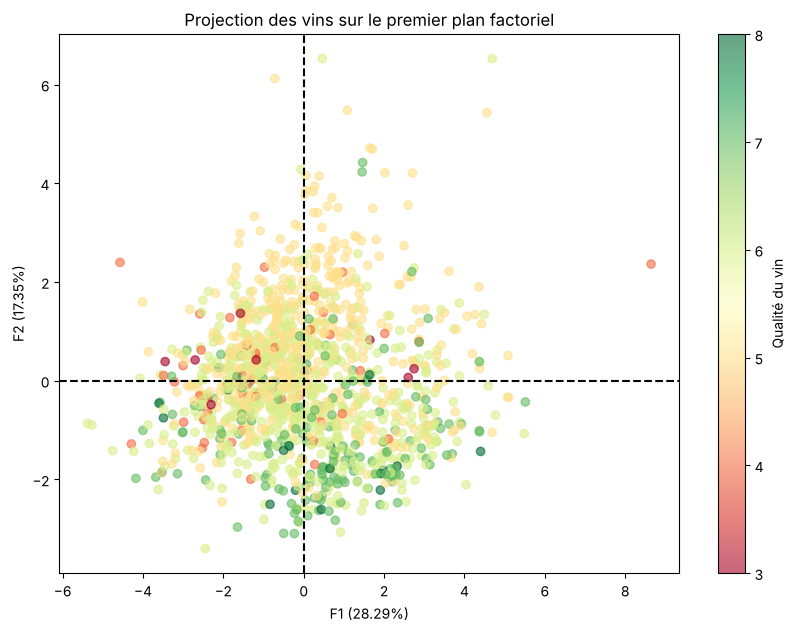

In [5]:
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=data['quality'], cmap='RdYlGn', alpha=0.6)
plt.colorbar(scatter, label='Qualité du vin')
plt.axhline(0, color='black', linestyle='--')
plt.axvline(0, color='black', linestyle='--')
plt.xlabel(f'F1 ({ratio[0]:.2%})')
plt.ylabel(f'F2 ({ratio[1]:.2%})')
plt.title('Projection des vins sur le premier plan factoriel')
plt.show()

**À retenir :** les deux premiers axes résument **45,6 %** de l'information. **F1 (28 %)** oppose les vins acides et denses (acidité fixe, acide citrique, densité) aux vins à pH élevé. **F2 (17 %)** est porté par le dioxyde de soufre (libre et total), à l'opposé de l'alcool. Les vins bien notés se placent plutôt en bas du plan, du côté de l'alcool : la qualité dépend d'une combinaison de variables, pas d'un seul axe.